In [2]:
import pandas as pd


In [3]:
# Reading the csv file 
data=pd.read_csv(r"C:\Users\VP\Downloads\bank.csv")
data.describe(include='str')
data.info()


<class 'pandas.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        11162 non-null  int64
 1   job        11162 non-null  str  
 2   marital    11162 non-null  str  
 3   education  11162 non-null  str  
 4   default    11162 non-null  str  
 5   balance    11162 non-null  int64
 6   housing    11162 non-null  str  
 7   loan       11162 non-null  str  
 8   contact    11162 non-null  str  
 9   day        11162 non-null  int64
 10  month      11162 non-null  str  
 11  duration   11162 non-null  int64
 12  campaign   11162 non-null  int64
 13  pdays      11162 non-null  int64
 14  previous   11162 non-null  int64
 15  poutcome   11162 non-null  str  
 16  deposit    11162 non-null  str  
dtypes: int64(7), str(10)
memory usage: 1.4 MB


In [4]:
from sklearn.model_selection import train_test_split
x=data.drop(columns='deposit')          
y=data['deposit'] 
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.30,random_state=42)        # Before doing Analysis And filling the N a values unknown values I am splitting the data
text=x_train.select_dtypes(include='str').columns.tolist()     # Ah here I am specifically taking Category column names
number=x_train.select_dtypes(include='number').columns.tolist()   # Here I'm taking specifically Numerical columns names

# Replacing the unknown values into nan  in the category colums 
import numpy as np
x_train[text]=x_train[text].replace('unknown',np.nan)
x_test[text]=x_test[text].replace('unknown',np.nan)

# Replacing the np.nan values into the most frequent values in the categorical column 
from sklearn.impute import SimpleImputer
si=SimpleImputer(strategy='most_frequent')
x_train[text]=si.fit_transform(x_train[text])
x_test[text]=si.transform(x_test[text])


# Performing one hot encoding in X train[text]
from sklearn.preprocessing import OneHotEncoder
ohe=OneHotEncoder(handle_unknown='ignore',sparse_output=False)
ohe.set_output(transform='pandas')

x_train_ohed=ohe.fit_transform(x_train[text])
x_train_final=pd.concat([x_train_ohed,x_train[number]],axis=1)


# Performing one hot encoding in X_test[text]
x_test_ohed=ohe.transform(x_test[text])
x_test_final=pd.concat([x_test_ohed,x_test[number]],axis=1)


In [5]:
print(x_train_final.shape, x_test_final.shape)

(7813, 47) (3349, 47)


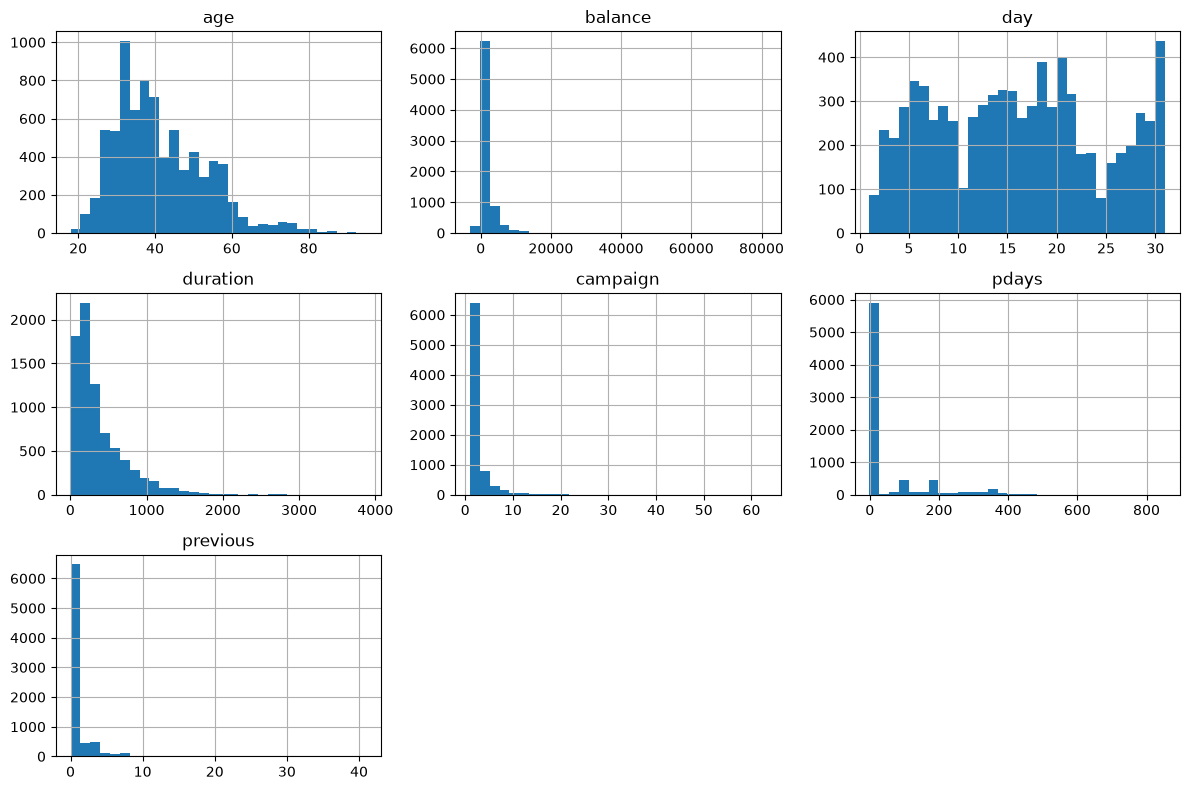

In [6]:
import matplotlib.pyplot as plt

x_train_number=x_train_final[number]
x_train_number.hist(bins=30, figsize=(12, 8))
plt.tight_layout()
plt.show()

In [7]:
temp=['age','day', 'duration', 'campaign']    # Performing the log transformation To convert into range of values
# for i in temp:
#     x_train_number[i]=np.log(x_train_number[i])

    

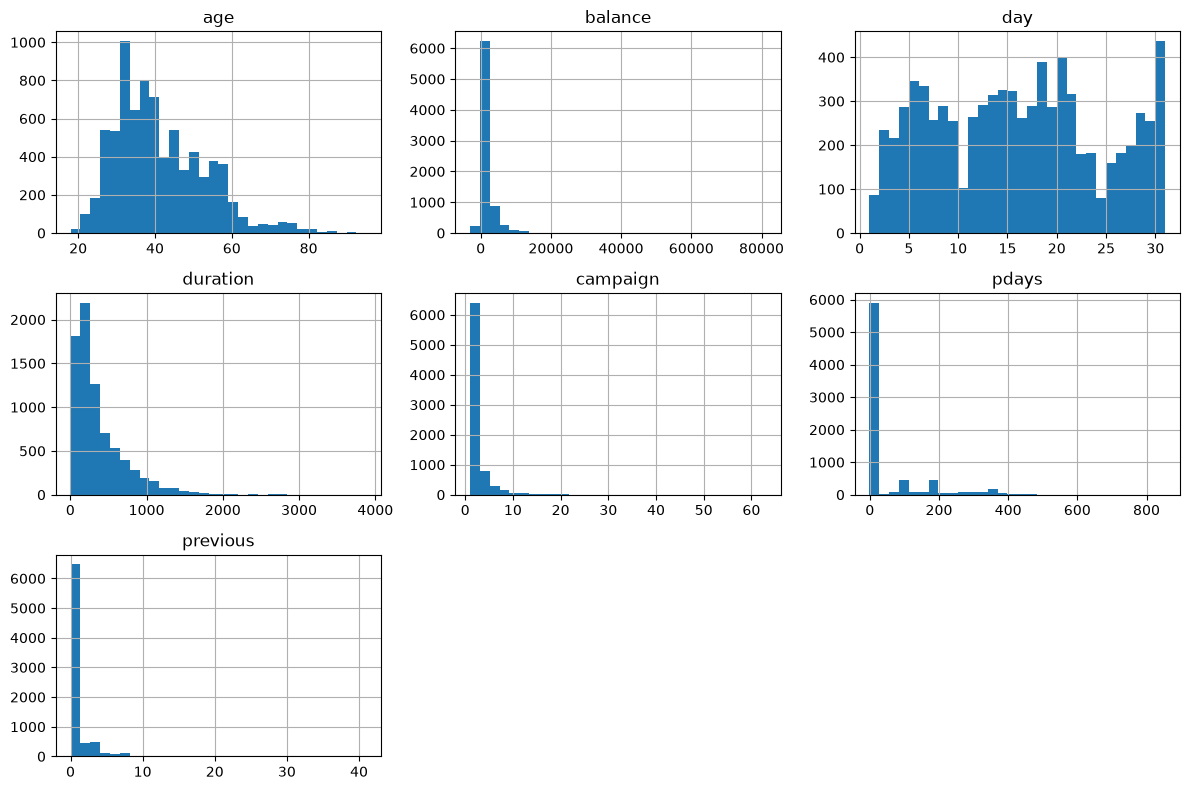

In [8]:
import matplotlib.pyplot as plt

x_train_number=x_train_final[number]
x_train_number.hist(bins=30, figsize=(12, 8))
plt.tight_layout()
plt.show()

In [9]:
from sklearn.preprocessing import StandardScaler
ss=StandardScaler()
x_train_number[temp]=ss.fit_transform(x_train_number[temp])

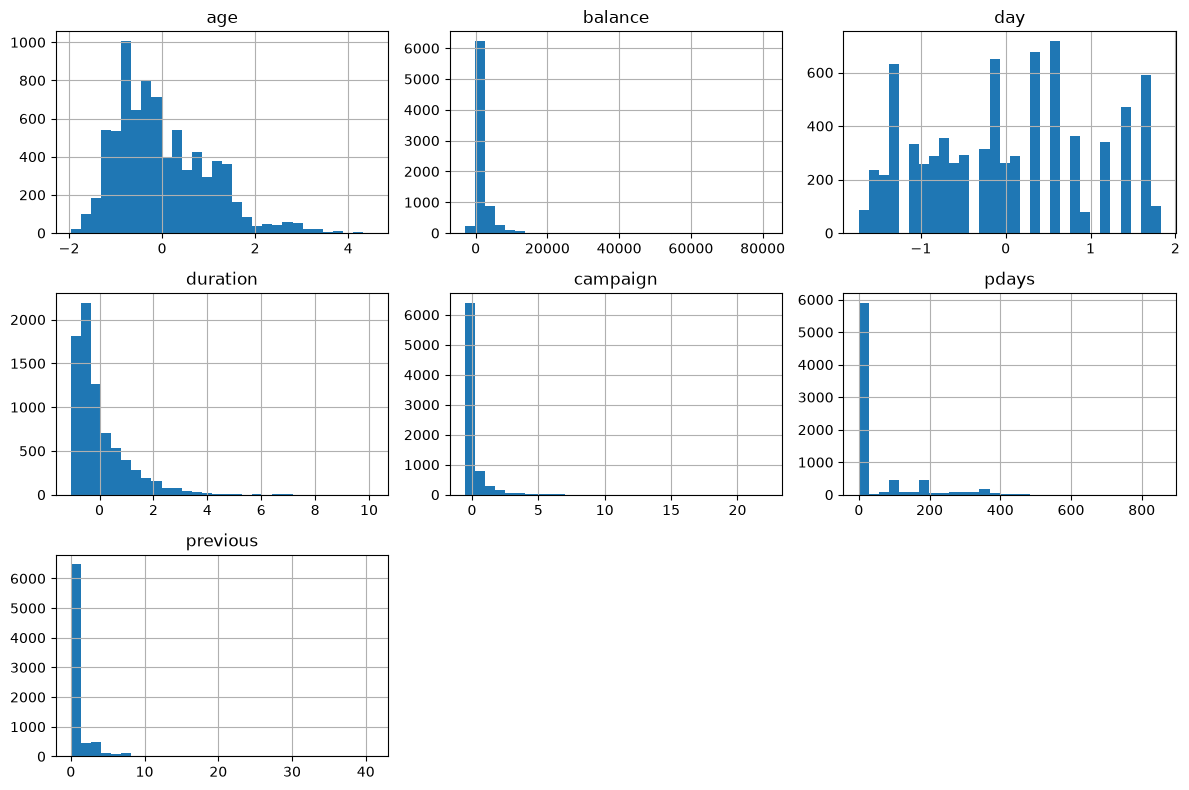

In [10]:
import matplotlib.pyplot as plt
x_train_number.hist(bins=30, figsize=(12, 8))
plt.tight_layout()
plt.show()

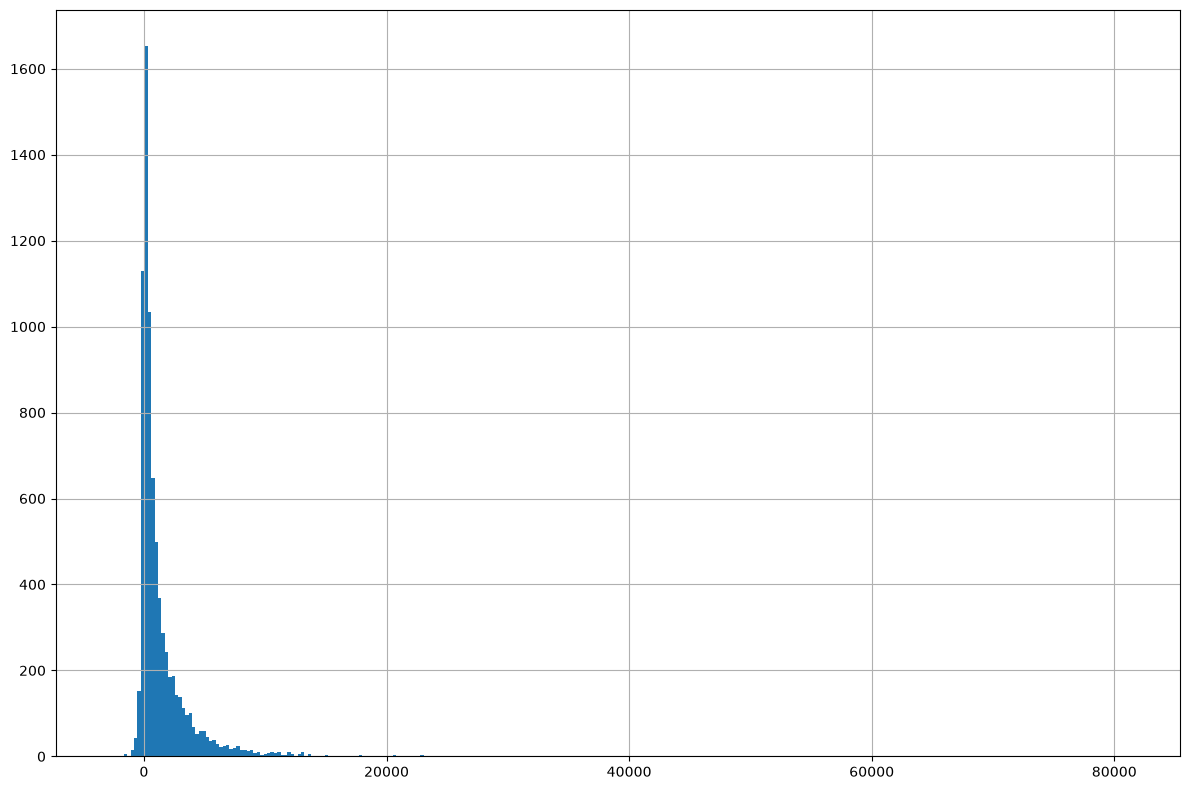

In [11]:
import matplotlib.pyplot as plt
x_train_number['balance'].hist(bins=300, figsize=(12, 8))
plt.tight_layout()
plt.show()

In [16]:
from sklearn.preprocessing import PowerTransformer
pt=PowerTransformer()
x_train_number['balance']=pt.fit_transform(x_train_number[['balance']])

In [24]:
x_train_number['pdays'].describe()

count    7813.000000
mean       49.952643
std       107.826919
min        -1.000000
25%        -1.000000
50%        -1.000000
75%        -1.000000
max       854.000000
Name: pdays, dtype: float64

In [28]:
from sklearn.preprocessing import PowerTransformer
pt=PowerTransformer(method='yeo-johnson')
x_train_number['pdays']=pt.fit_transform(x_train_number[['pdays']])

In [29]:
x_train_number

,age,balance,day,duration,campaign,pdays,previous
7968,1.330255,-0.061565,-0.784541,2.608028,-0.550775,-0.575910,0
1456,-0.610758,-0.071051,-0.309441,0.980204,-0.550775,-0.575910,0
361,-0.020015,-0.445676,-1.734742,0.315195,2.387568,-0.575910,0
812,0.401944,1.044121,0.284434,0.387479,1.652982,-0.575910,0
1092,-1.117109,1.058721,1.472184,1.153684,-0.550775,-0.575910,0
...,...,...,...,...,...,...,...
5734,0.486336,-0.134507,-0.546991,-0.838450,-0.183482,-0.575910,0
5191,-1.117109,-0.399046,0.046884,0.228455,-0.183482,1.720243,4
5390,-0.526366,0.010609,0.521984,-0.500163,3.856739,-0.575910,0
860,0.823903,-0.140429,1.115859,0.005822,0.918397,-0.575910,0


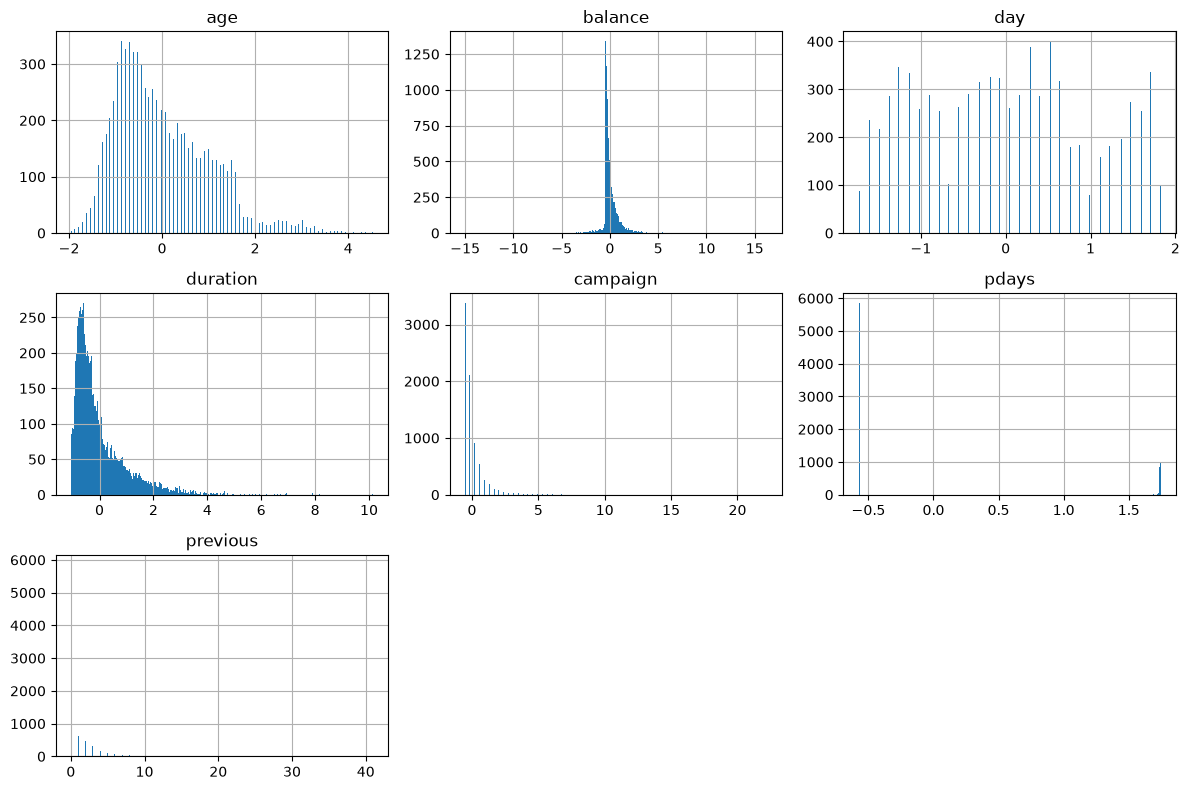

In [30]:
import matplotlib.pyplot as plt
x_train_number.hist(bins=300, figsize=(12, 8))
plt.tight_layout()
plt.show()

In [58]:
x_train_final=x_train_final.drop(x_train_final[number].columns.tolist(),axis=1)

In [51]:
x_train_final=x_train_final.dropna()

In [59]:
x_train_final=pd.concat([x_train_final,x_train_number.round(2)],axis=1)

In [61]:
x_train_final.to_csv('BANK OUT.csv')